# Agrupamiento de equipos | LPF 2026

El análisis usa los 480 partidos de zonas. Cada equipo se describe
con goles a favor por partido, goles en contra por partido y
proporción de empates. Las tres variables se estandarizan antes de
aplicar K-means. El agrupamiento describe el rendimiento en el marcador.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from lpf_analytics.clustering import (
    agrupar_equipos,
    evaluar_grupos,
    indicadores_rendimiento,
)

actual = Path.cwd()
raiz = next(
    carpeta for carpeta in (actual, *actual.parents)
    if (carpeta / "pyproject.toml").is_file()
)
partidos = pd.read_csv(
    raiz / "data/raw/LPF_2026_partidos.csv", encoding="utf-8-sig"
)
indicadores = indicadores_rendimiento(partidos)

## Elección de la cantidad de grupos

Se compararon de dos a seis grupos mediante la silueta y 40 submuestras
de 24 equipos. En cada submuestra se ajustó de nuevo el modelo y se
comparó su asignación de los 30 clubes con la de referencia mediante
el índice de Rand ajustado (ARI).

Tres grupos dieron la mayor mediana de ARI (0,770). Seis grupos
obtuvieron una silueta ligeramente mayor (0,312 frente a 0,301) y un
percentil 10 de ARI superior. Se eligieron tres para priorizar la
estabilidad mediana y facilitar la interpretación.

In [6]:
display(evaluar_grupos(indicadores).round(3))

,Silueta,Equipos_por_grupo,ARI_mediana,ARI_percentil_10
Grupos,,,,
2,0.273,"17, 13",0.523,0.040
3,0.301,"16, 7, 7",0.770,0.495
4,0.287,"13, 8, 6, 3",0.449,0.283
5,0.275,"9, 8, 5, 5, 3",0.454,0.329
6,0.312,"8, 7, 4, 4, 4, 3",0.716,0.538


In [7]:
agrupados = agrupar_equipos(indicadores, k=3)
por_grupo = agrupados.groupby("Grupo")
perfiles = por_grupo.mean()
perfiles.insert(0, "Equipos", por_grupo.size())

display(perfiles.round(3))
display(agrupados.sort_values("Grupo").round(3))

,Equipos,GF_por_partido,GC_por_partido,Proporcion_empates
Grupo,,,,
1,16,1.045,0.982,0.357
2,7,0.875,1.362,0.241
3,7,1.402,1.058,0.228


,GF_por_partido,GC_por_partido,Proporcion_empates,Grupo
Equipo,,,,
Boca Juniors,1.438,0.719,0.375,1
Argentinos Juniors,1.156,0.844,0.281,1
Vélez Sarsfield,1.344,0.906,0.438,1
Independiente,1.219,1.125,0.344,1
Defensa y Justicia,1.219,1.125,0.344,1
Barracas Central,1.000,0.875,0.344,1
Belgrano,1.062,0.875,0.312,1
Lanús,1.156,0.844,0.344,1
Huracán,0.969,0.906,0.344,1


## Perfiles en la escala original

Boca quedó en el grupo 1, que promedió más empates y menos
goles recibidos por partido. El grupo 2 tuvo el menor promedio goleador
y el mayor promedio de goles en contra. El grupo 3 registró el
mayor promedio goleador.

El gráfico muestra los dos promedios de goles. La proporción de
empates también interviene en la asignación de los grupos.

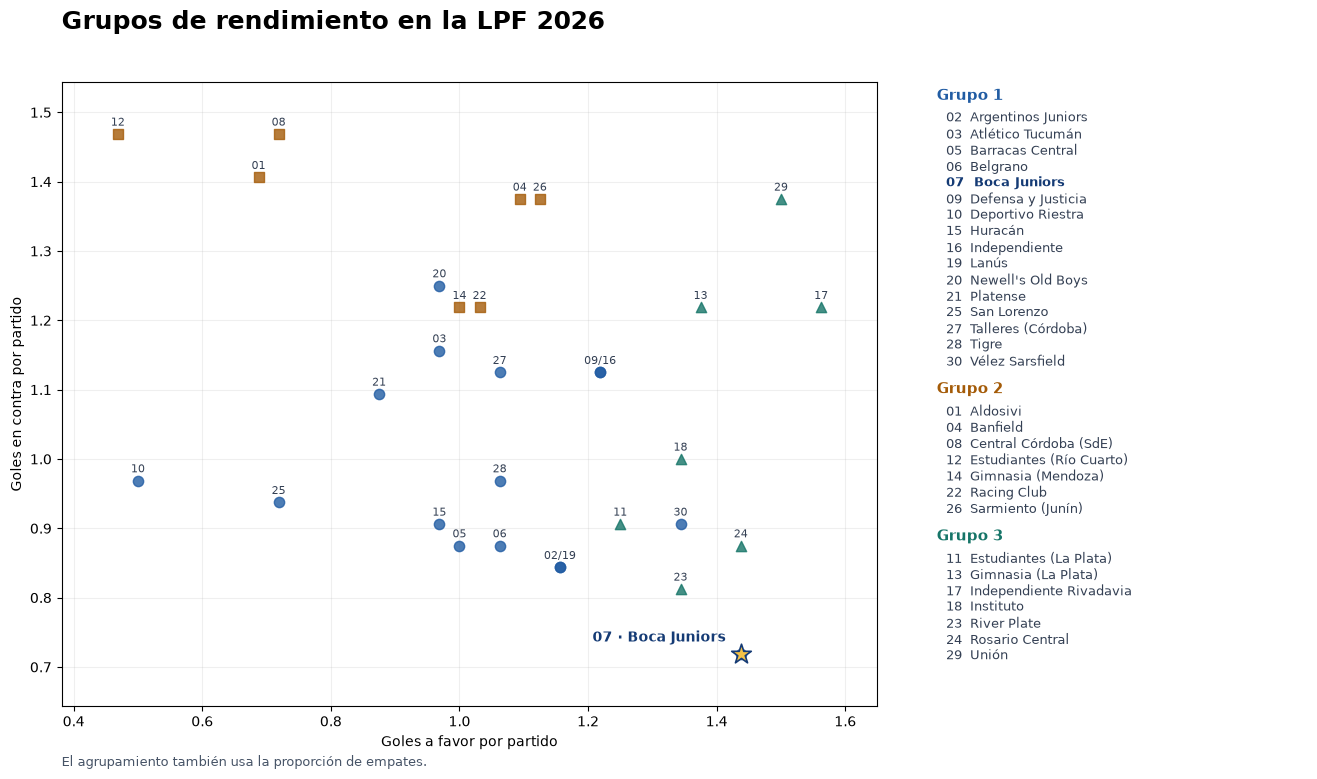

In [8]:
vista = agrupados.sort_index().copy()
vista["Numero"] = range(1, len(vista) + 1)

colores = {1: "#215CA3", 2: "#A45B08", 3: "#167568"}
marcadores = {1: "o", 2: "s", 3: "^"}

figura, (eje, listado) = plt.subplots(
    1, 2, figsize=(14, 8),
    gridspec_kw={"width_ratios": [2.2, 1]},
)
figura.subplots_adjust(
    left=0.08, right=0.97, bottom=0.11, top=0.89, wspace=0.10
)
figura.suptitle(
    "Grupos de rendimiento en la LPF 2026",
    x=0.08, ha="left", fontsize=18, weight="bold",
)

for grupo, clubes in vista.groupby("Grupo"):
    eje.scatter(
        clubes["GF_por_partido"], clubes["GC_por_partido"],
        color=colores[grupo], marker=marcadores[grupo], s=55, alpha=0.8,
    )

otros = vista.drop(index="Boca Juniors")
por_posicion = otros.groupby(["GF_por_partido", "GC_por_partido"])
for (gf, gc), clubes in por_posicion:
    numeros = "/".join(f"{numero:02d}" for numero in clubes["Numero"])
    eje.annotate(
        numeros, (gf, gc),
        xytext=(0, 6), textcoords="offset points",
        ha="center", fontsize=8, color="#344054",
    )

boca = vista.loc["Boca Juniors"]
posicion_boca = (boca["GF_por_partido"], boca["GC_por_partido"])
eje.scatter(
    *posicion_boca, marker="*", s=220,
    color="#F4C247", edgecolor="#153B75", linewidth=1.2, zorder=5,
)
eje.annotate(
    f'{int(boca["Numero"]):02d} · Boca Juniors', posicion_boca,
    xytext=(-11, 9), textcoords="offset points", ha="right",
    weight="bold", color="#153B75",
)
eje.set(
    xlabel="Goles a favor por partido",
    ylabel="Goles en contra por partido",
)
eje.margins(x=0.08, y=0.10)
eje.set_axisbelow(True)
eje.grid(alpha=0.2)

listado.axis("off")
altura = 0.99
for grupo, clubes in vista.groupby("Grupo"):
    listado.text(
        0, altura, f"Grupo {grupo}", color=colores[grupo],
        weight="bold", fontsize=11, va="top",
    )
    altura -= 0.037

    for equipo, fila in clubes.iterrows():
        es_boca = equipo == "Boca Juniors"
        listado.text(
            0.025, altura, f'{int(fila["Numero"]):02d}  {equipo}',
            color="#153B75" if es_boca else "#344054",
            weight="bold" if es_boca else "normal",
            fontsize=9.5, va="top",
        )
        altura -= 0.026

    altura -= 0.017

figura.text(
    0.08, 0.035, "El agrupamiento también usa la proporción de empates.",
    fontsize=9, color="#475467",
)
plt.show()